# Théorie :

**Problème d'un MLP sur une image** : il faut l'applatir en vecteur, on perds la structure spatiale et necessite bcp de poids + instable aux transformation géométrique (translation, symétrie ...).  
On a donc partir sur une structure différentes : **Les CNNs**  
On va utiliser un ensemble de filtres (somme pondérées sur l'imagette ...). Le poids de chaque filtre est commun à toute l'image, chaque filtre devient un détecteur de motif (ligne droite, courbe droite ...)  

Un CNN contient plusieurs couches :  
1. **Convolution** : Produit une feature map par filtre. (Notions à maitriser : noyau, stride, padding, nombre de canaux d'entrée et de sortie.)
2. **Activation (ReLu)** : comme dans le MLP
3. **Pooling** (max pooling) : réduit la taille de la carte et donne une tolérance aux petits décalages.
4. **Aplatissement puis couche dense** : à la fin, on retombe sur un MLP qui classe à partir des motifs détectés (Cette fois, on ne fera pas le MLP entier mais simplifié avec la backprof intégrée à PyTorch)
5. **Sortie** : softmax avec 2 classes (carré/cercle), ou 1 neurone sigmoïde. Loss = cross-entropy

**Apprentissage** : même principe que MLP (boucle {forward, loss, backprog, maj des w} jusqu'à un stop). La nouveauté est que le gradient d'une convolution est lui-même une convolution (avec le filtre retourné), et que celui du max pooling n'est transmis qu'à la position du maximum.

## Plan large proposé par claude
1. Fait (comprendre convolution)
1. Fait (jeu donnée carré/cercle)
2. **Pipeline de données** : normalisation, séparation train/validation/test, mélange, batchs.
3. **Modèle minimal** : 1 à 2 blocs conv + ReLU + pooling, puis une couche dense. Commence petit.
4. **Boucle d'entraînement** : perte, optimiseur, suivi des courbes loss/accuracy (train vs validation).
5. **Évaluation** : accuracy, matrice de confusion, et visualisation des images mal classées.
6. **Comprendre ce que le modèle apprend** : afficher les filtres et les feature maps.
7. **Test final sur tes dessins à la main** : prétraitement identique (redimensionnement, inversion des couleurs si besoin), puis prédiction.
8. **Améliorations** (optionnel) : augmentation de données (translation, rotation, bruit, épaisseur du trait), dropout, comparaison avec ton MLP.

![alt text](TP-CNN-architecture-1.jpg)

### *1. Notions liés à la convolution*
#### *Vocabulaire*
**Noyau :**  
- imagette issus de la matrice qu'on fait glisser sur l'image (3x3 par exemple).
- A chaque position légale, on multiplie terme à terme puis on somme, et on rend 1 résultat. Les poids sont les w issus de l'entrainement.

**Stride (pas) :**  
- Combien de case le noyau se déplace

**Padding :**  
- Présence ou non de bordure rajouté autour de l'entrée
  - padding = 'valid' : aucun rajout. Sortie de taille -2 sur chaque axe
  - padding = 'same' : on rajoute des valeurs sur les contours de l'entrée, qui fait que la sorti est de taille identique à l'entrée (np.pad sur l'entrée)

**Canaux :**  
- Nombre c de matrices (x,y) utilisés pour representer l'image de taille (c,x,y)

#### *Taille impliqué dans la convolution :*
1. **Entrée**
- `C_in` : nombre de canaux d'entrée
- `H` (ou `n`) : hauteur de l'image (donc nbr de lignes)
- `W` (ou `self.self.P`) : largeur ... (nbr de colonnes)
  - Forme de l'entrée : `(C_in, H, W)`   
2. **Hyperparamètres de la couche**
- `C_out` : nombre de filtres, donc nbr canaux de sortie
- `k` : taille du noyau (k*k, souvent 3)
- `s` : stride, le pas de déplacement
- `P`: padding, nombre de cases ajoutées sur les bords (avec `'valid'`, P = 0)  
3. **Intermédiaire : ce que la couche contient**
- Noyau : matrice `k*k` pour un canal
- Filtre : `C_in` noyaux, de forme `(C_in, k, k)`
- Tous les filtres ensemble : forme (`(C_out, C_in, k, k)`)
- Biais : `C_out` valeurs, une par filtre
- Nombre de paramètres appris : `C_out * C_in * k * k + C_out`  
4. **Sortie**
- De forme `(C_out, H_out, W_out)`
- $H_{out} = floor[(H - k + 2P)/s] +1$
- $W_{out} = floor[(W - k + 2P)/s] +1$
  - avec `'valid'` et un stride de 1, on retrouve `H-k+1` et `W-k+1`, soit `H-2` et `W-2` pour k = 3

#### *Resumé :*
**Entrée** **$\to$** Si l'image à plusieurs canaux, on repère l'axe des canaux (le plus petit) et on remet dans l'ordre `(C_in, H, W)` au besoin.  

**Noyaux** **$\to$** On crée `C_out` filtres de forme `(C_in, k, k)` : `(C_out, C_in, k, k)` pour l'ensemble ou un dict ...    
**$\to$** Les poids sont initialisés aléatoirement, et rajoute d'un biais par filtre (soit `C_out` biais tous initialisé à 0)  

**Padding** **$\to$** `'valid'` donne `P=0`, `'same'` donne `P = (k-1)//2`, et un entier est utilisé tel quel. On pad uniquement sur `H` et `W` (pas les canaux)  

**Convolution** **$\to$** pour chaque filtre, on fait glisser la fenetre sur `df`. La map de sortie est de taille `(H_out, W_out)`.  
**$\to$** On itère pour chaque fenetre valide, et on recupere la somme pondérée par poids du noyau (multiplication terme a terme noyau * fenetre), et on rajoute le biais.  

**Sortie** **$\to$** On fait un `np.stack` des maps, ce qui donne un matrice 3D `(C_out, H_out, W_out)`. Chaque couche de sortie correspond à un filtre.  


In [ ]:
def convolution(self, M):
    df = M.copy()
    format = list(df.shape[-2:])

    if self.P > 0:
        df = np.pad(df, [(0, 0)] * (df.ndim - 2) + [(self.P, self.P), (self.P, self.P)])

    N_out = []
    for c, noyau in self.noyau.items():
        N = np.zeros((
            (format[0] - self.k + 2 * self.P) // self.stride + 1,
            (format[1] - self.k + 2 * self.P) // self.stride + 1
        ))
            
        for i in range(N.shape[0]):
            for j in range(N.shape[1]):
                fenetre = df[
                    ...,
                    i * self.stride:i * self.stride + self.k,
                    j * self.stride:j * self.stride + self.k
                ]

                # if fenetre.shape[-2:] == (self.k, self.k):
                N[i,j] = np.sum(fenetre * noyau) + self.biais[c]
        N_out.append(N)
    return np.stack(N_out)

### *2. Notion liées au maxpooling*

In [ ]:
def maxpooling(self, M):
    df = M.copy()
    format = list(df.shape)
    format[-1] = (format[-1] - self.k_maxpooling) // self.stride_maxpooling + 1
    format[-2] = (format[-2] - self.k_maxpooling) // self.stride_maxpooling + 1

    N_out = np.zeros(format)
    for i in range(N_out.shape[-2]):
        for j in range(N_out.shape[-1]):
            fenetre = df[
                ...,
                i * self.stride_maxpooling:i * self.stride_maxpooling + self.k_maxpooling,
                j * self.stride_maxpooling:j * self.stride_maxpooling + self.k_maxpooling
            ]                
            N_out[...,i,j] = np.max(fenetre, axis=(-1,-2))
    return N_out

In [2]:
import numpy as np
import torch
import torch.nn as nn
from sklearn.datasets import fetch_openml
from torch.utils.data import DataLoader, TensorDataset


## Modèle

In [3]:
X_mnist, y_mnist = fetch_openml('mnist_784', return_X_y=True, as_frame=False)
X_mnist = X_mnist.reshape(-1, 28, 28) / 255.        # (N, 784) -> (N, 28, 28), valeurs dans [0, 1]
y_mnist = y_mnist.astype(np.int64)

Information pour claude à lire :
On ne veux pas passer par des blocs "boite noir" de pytorch, mais faire a la main les étapes.

In [118]:
class Conv:
    def __init__(self, C_in=1, C_out=6, kernel=3, stride=1, padding="valid"):
        '''
        C_in : nbr de canaux d'entrée - 3 pour RGB ...
        C_out : nombre de filtre et donc nombre de canaux en sortie de convolution
        kernel : taille k du noyau (k x k)
        stride : pas de déplacement de la fenêtre d'application du noyau
        padding : 'valid' (P=0), 'same' (P=(k-1)//2) ou entier >= 0
        '''
        self.C_in, self.C_out = C_in, C_out
        self.k, self.stride = kernel, stride
        self.padding = padding

        # Traduction du padding str -> int
        pad_dict = {'valid': 0, 'same': (self.k - 1)//2}
        if padding in pad_dict:
            self.P = pad_dict[padding]
        elif isinstance(padding, int):
            self.P = padding
        else:
            raise KeyError("Definir padding pour 'valid', 'same' ou entier")

        # Initialisation des poids (C_out, C_in, k, k)
        self.noyau = (torch.randn(C_out, C_in, kernel, kernel) / (C_in * kernel**2) ** 0.5).requires_grad_()
        self.biais = torch.zeros(C_out, requires_grad = True)

    def parameters(self):
        return [self.noyau, self.biais]

    def forward(self, x):                   # x : (N, C_in, H, W)
        if x.shape[1] != self.C_in:
            raise ValueError(f"Conv attend {self.C_in} canaux en entrée, recu {x.shape[1]}")
        if self.P > 0:
            x = torch.nn.functional.pad(x, (self.P, self.P, self.P, self.P))
        H_out = (x.shape[-2] - self.k) // self.stride + 1
        W_out = (x.shape[-1] - self.k) // self.stride + 1 
        if H_out <= 0 or W_out <= 0:
            raise ValueError(f"Image trop petite ({x.shape[-2]}x{x.shape[-1]}) pour un noyau {self.k}x{self.k}")

        rows = []
        for i in range(H_out):
            cols = []
            for j in range(W_out):
                fenetre = x[:, :,                               # (N, C_in, k, k)
                            i*self.stride:i*self.stride+self.k,
                            j*self.stride:j*self.stride+self.k]
                cols.append((fenetre[:, None] * self.noyau).sum(dim=(-3,-2,-1)) + self.biais) # (N, C)
            rows.append(torch.stack(cols, dim=-1))  # (N, C, W_out)
        return torch.stack(rows, dim=-2)            # (N, C, H_out, W_out)

class ReLu:
    def parameters(self):
        return []

    def forward(self, x):
        return torch.relu(x) # max(0,x)

class MaxPool:
    def __init__(self, kernel=2, stride=2):
        self.k = kernel
        self.stride = stride

    def parameters(self):
        return []

    def forward(self, x):   # x : (N, C, H, W), pas de padding possible
        H_out = (x.shape[-2] - self.k) // self.stride + 1
        W_out = (x.shape[-1] - self.k) // self.stride + 1
        if H_out <= 0 or W_out <= 0:
            raise ValueError(f"Image trop petite ({x.shape[-2]}x{x.shape[-1]}) pour un noyau {self.k}x{self.k}")

        rows = []
        for i in range(H_out):
            cols = []
            for j in range(W_out):
                fenetre = x[...,                                # (N, C, k, k)
                            i*self.stride:i*self.stride+self.k,
                            j*self.stride:j*self.stride+self.k]
                cols.append(torch.amax(fenetre, dim=(-2,-1)))   # (N, C)
            rows.append(torch.stack(cols, dim=-1))             # (N, C, W_out)
        return torch.stack(rows,dim=-2)                         # (N, C, H_out, W_out)

class Flatten:
    def parameters(self):
        return []

    def forward(self, x):
        return x.flatten(1)     # (N, C, H, W) -> (N, C*H*W)

class Dense:
    def __init__(self, n_out):
        self.n_in = None    # Connu seulement après le 1er passage
        self.n_out = n_out
        self.W = None
        self.b = None

    def parameters(self):
        if self.W is None:
            raise RuntimeError("Dense enconre non initialisé : faire tourner le modèle (premier passage)")
        return [self.W, self.b]

    def forward(self, x):
        if x.ndim != 2:
            raise ValueError(f"Dense attend une entrée (N, n_in), recu {x.shape} : oubli de Flatten ?")
        if self.W is None:
            self.n_in = x.shape[1]
            self.W = (torch.randn(self.n_in, self.n_out) / self.n_in ** 0.5).requires_grad_()
            self.b = torch.zeros(self.n_out, requires_grad=True)
        elif x.shape[1] != self.n_in:
            raise ValueError(f"Dense attend {self.n_in} entrées, recu {x.shape[1]}")
        return x @ self.W + self.b # logits (softmax dans la cross-entropy)

class loss:
    def __init__(self, loss='cross-entropy'):
        self.loss = loss

    def CE(self):
        pass




class Modele:
    def __init__(self, couches, input_shape=(1, 28, 28), EPOCH=100, lr=0.1):
        '''
        couches : liste de couches appliquées dans l'ordre
        input_shape : (C, H, W) d'une image, pour le passage à blanc qui fixe la taille des Dense
        '''
        self.couches = couches
        self.input_shape = input_shape
        self.EPOCH = EPOCH
        self.lr = lr

    def parameters(self):
        p = []
        for c in self.couches:
            p.extend(c.parameters())
            # p.append(c.parameters())
        return p
    
    def forward(self, x):
        for c in self.couches:
            x = c.forward(x)
        return x

    def backward(self, x):
        return 
    
    def fit(self, x, y):
        self.perf_fit = []
        for epoch in range(self.EPOCH):
            I = x.clone()

            yhat = self.forward(I)
            p = self.parameters()

            loss = -torch.log_softmax(yhat,dim=1)[torch.arange(yhat.shape[0]),y].mean()

            for param in p:
                param.grad = None
            
            loss.backward()
            with torch.no_grad():
                for param in p:
                    param -= self.lr * param.grad   # back propagation du gradient (in place fonctionne dans la boucle)
            
            accuracy = (torch.argmax(yhat, dim=1) == y).float().mean().item()
            print([loss.item(), accuracy])
            self.perf_fit.append([loss.item(), accuracy])
        return "end"

    def predict(self, x):
        return self.forward(x)
        


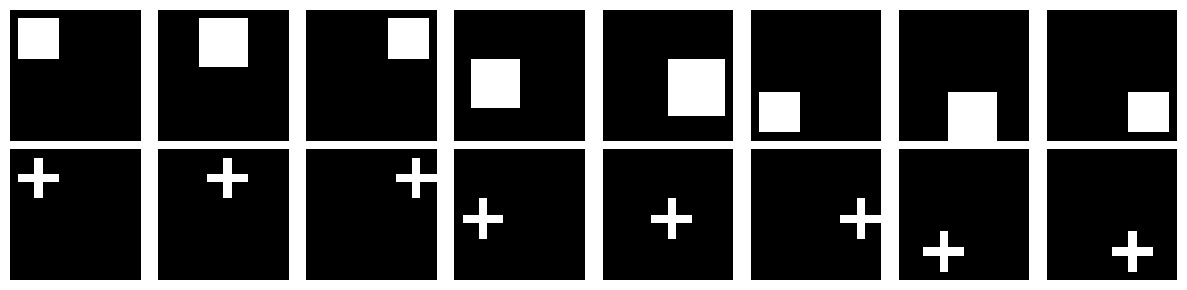

[0.6820870637893677, 0.625]
[0.6271482706069946, 0.5625]
[0.5883463621139526, 0.625]
[0.5569199323654175, 0.6875]
[0.5286615490913391, 0.8125]
[0.5025959014892578, 0.9375]
[0.4782387912273407, 0.9375]
[0.4551353454589844, 0.9375]
[0.43302077054977417, 0.9375]
[0.4118198752403259, 0.9375]
[0.3914104402065277, 0.9375]
[0.3718118369579315, 1.0]
[0.35300102829933167, 1.0]
[0.3349730670452118, 1.0]
[0.31770604848861694, 1.0]
[0.3011983036994934, 1.0]
[0.28544479608535767, 1.0]
[0.27041903138160706, 1.0]
[0.2561455965042114, 1.0]
[0.2426113486289978, 1.0]
[0.22976937890052795, 1.0]
[0.2176416963338852, 1.0]
[0.20620512962341309, 1.0]
[0.19543534517288208, 1.0]
[0.1853393167257309, 1.0]
[0.17590491473674774, 1.0]
[0.16698086261749268, 1.0]
[0.15873922407627106, 1.0]
[0.1510884016752243, 1.0]
[0.14390568435192108, 1.0]
[0.13716185092926025, 1.0]
[0.13083595037460327, 1.0]
[0.12491089105606079, 1.0]
[0.11934433877468109, 1.0]
[0.11411551386117935, 1.0]
[0.10920059680938721, 1.0]
[0.104578651487

'end'

In [121]:
import matplotlib.pyplot as plt

# 16 images : 8 carrés puis 8 croix, de taille 16x16
images = torch.zeros((16, 1, 16, 16), dtype=torch.float32) # (N=16 images, C=1 canal de couleur, H=16, W=16)
y = torch.cat((torch.zeros(8, dtype=int),torch.ones(8,dtype=int)))

# 8 carrés
carres = [
    (1, 1, 5), (5, 1, 6), (10, 1, 5), (2, 6, 6),
    (8, 6, 7), (1, 10, 5), (6, 10, 6), (10, 10, 5)
]

for i, (x0, y0, taille) in enumerate(carres):
    images[i, 0, y0:y0 + taille, x0:x0 + taille] = 1

# 8 croix
croix = [
    (1, 1), (6, 1), (11, 1), (1, 6),
    (6, 6), (11, 6), (3, 10), (8, 10)
]

for i, (x0, y0) in enumerate(croix, start=8):
    images[i, 0, y0:y0 + 5, x0 + 2:x0 + 3] = 1
    images[i, 0, y0 + 2:y0 + 3, x0:x0 + 5] = 1

fig, axes = plt.subplots(2, 8, figsize=(12, 3))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i, 0], cmap="gray", vmin=0, vmax=1)
    ax.axis("off")

plt.tight_layout()
plt.show()

c1 = Conv(C_in=1,C_out=6,kernel=3,stride=1,padding='valid')
a1 = ReLu()
m1 = MaxPool(kernel=2,stride=2)
f1 = Flatten()
d1 = Dense(n_out=2)

couches = [c1, a1, m1, f1, d1]
model = Modele(couches, input_shape=(1, 16, 16), EPOCH=100)
# model.forward(images)
# model.parameters()
model.fit(images, y)



In [ ]:
yhat = torch.tensor([[ 0.4736,  0.0703],
        [ 0.7397,  0.5961],
        [-0.0315, -0.4884],
        [ 0.3377, -0.0139],
        [ 0.2653, -0.6422],
        [ 0.3977,  0.4083],
        [-0.2687, -0.4967],
        [ 0.5517, -0.4852],
        [ 0.3269,  0.0164],
        [ 0.4079,  0.4287],
        [ 0.0061, -0.3900],
        [ 0.2111,  0.1498],
        [-0.4414, -0.0725],
        [ 0.1596, -0.0151],
        [-0.0096, -0.0997],
        [ 0.2251, -0.3084]])

print(yhat,y)
print(torch.log_softmax(yhat[torch.arange(yhat.shape[0]), torch.as_tensor(y, dtype=torch.long)]))

tensor([[ 0.4736,  0.0703],
        [ 0.7397,  0.5961],
        [-0.0315, -0.4884],
        [ 0.3377, -0.0139],
        [ 0.2653, -0.6422],
        [ 0.3977,  0.4083],
        [-0.2687, -0.4967],
        [ 0.5517, -0.4852],
        [ 0.3269,  0.0164],
        [ 0.4079,  0.4287],
        [ 0.0061, -0.3900],
        [ 0.2111,  0.1498],
        [-0.4414, -0.0725],
        [ 0.1596, -0.0151],
        [-0.0096, -0.0997],
        [ 0.2251, -0.3084]]) tensor([0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1])
tensor([ 0.4736,  0.7397, -0.0315,  0.3377,  0.2653,  0.3977, -0.2687,  0.5517,
         0.0164,  0.4287, -0.3900,  0.1498, -0.0725, -0.0151, -0.0997, -0.3084])
